# Exploring VinBigData Chest X-rays

**Group 10 | Deep Learning | Data understanding notebook**

## 1. Locate the data and set up the notebook

### 1.1 Imports and analysis settings

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

### 1.2 Analysis options

The default hash audit checks **all** prepared PNG files, not a random subset. Set `RUN_FULL_SHA256 = False` for a quick trial run; in that case, the result must be described as a sample-based check.

In [2]:
SEED = 2026
IMAGE_SAMPLE_PER_SPLIT = 50
DICOM_HEADER_SAMPLE = 60
RUN_FULL_SHA256 = True

pd.set_option("display.max_columns", 25)
pd.set_option("display.max_rows", 22)

### 1.3 Where are the project files?

In [3]:
PROJECT_ROOT = None
DATA_DIR = None         
RAW_CSV = None       
DICOM_ZIP = None     

CLASS_NAMES = [
    "Aortic enlargement", "Atelectasis", "Calcification", "Cardiomegaly",
    "Consolidation", "ILD", "Infiltration", "Lung Opacity", "Nodule/Mass",
    "Other lesion", "Pleural effusion", "Pleural thickening", "Pneumothorax",
    "Pulmonary fibrosis", "No finding"
]
DISEASES = CLASS_NAMES[:-1]
NO_FINDING = CLASS_NAMES[-1]
OUTPUT_DIR = Path.cwd() / "eda_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

In [4]:
project_candidates = [
    Path.cwd(), *Path.cwd().parents,
    Path.cwd() / "chest-xray-classification-system",
    Path(r"D:/_chest_xray_eda_workspace/chest-xray-classification-system")
]
PROJECT_ROOT = (Path(PROJECT_ROOT) if PROJECT_ROOT is not None else next(
    (p for p in project_candidates if (p / "generate_data.py").is_file()
     and (p / "config.py").is_file()), None))
dataset_candidates = (
    ([PROJECT_ROOT / "datasets" / "processed"] if PROJECT_ROOT else [])
    + [Path(r"D:/_chest_xray_eda_workspace/datasets/processed"),
       Path.cwd() / "datasets" / "processed"]
)
DATA_DIR = (Path(DATA_DIR) if DATA_DIR is not None else next(
    (p for p in dataset_candidates if all((p / f"{part}.csv").is_file()
        for part in ("train", "val", "test"))), None))
if DATA_DIR is None:
    raise FileNotFoundError(
        "Processed data not found. Set DATA_DIR above or run python download_dataset.py.")
DATA_DIR = DATA_DIR.resolve()

In [5]:
raw_candidates = [DATA_DIR.parent / "raw" / "train.csv",
                  Path(r"D:/_chest_xray_eda_workspace/raw/train.csv")]
RAW_CSV = Path(RAW_CSV) if RAW_CSV is not None else next(
    (p for p in raw_candidates if p.is_file()), None)

zip_candidates = [
    Path(r"D:/_chest_xray_eda_workspace/raw/vinbigdata-chest-xray-abnormalities-detection.zip"),
    DATA_DIR.parent / "raw" / "train.zip"
]
DICOM_ZIP = Path(DICOM_ZIP) if DICOM_ZIP is not None else next(
    (p for p in zip_candidates if p.is_file()), None)

print("Project:", PROJECT_ROOT or "Not required")
print("Processed dataset:", DATA_DIR)
print("Raw annotations:", RAW_CSV or "Unavailable; optional sections will be skipped")
print("Original DICOM:", DICOM_ZIP or "Unavailable; spatial-size analysis will be skipped")

Project: D:\_chest_xray_eda_workspace\chest-xray-classification-system
Processed dataset: D:\_chest_xray_eda_workspace\datasets\processed
Raw annotations: D:\_chest_xray_eda_workspace\raw\train.csv
Original DICOM: D:\_chest_xray_eda_workspace\raw\vinbigdata-chest-xray-abnormalities-detection.zip


**Check before proceeding.** The raw CSV and DICOM archive are optional, but the prepared split CSVs are required. If the notebook finds the wrong copy of the dataset, specify `DATA_DIR`, `RAW_CSV` and `DICOM_ZIP` explicitly in the setup cells above and rerun.

## 2. What is one observation?

The annotation table contains repeated rows for some X-rays because different radiologists can draw multiple boxes. Our classification problem instead works with **one image and one binary label vector** per observation. We therefore count images, not annotation rows, when estimating label prevalence.

### 2.1 Load the three prepared splits

In [6]:
frames = {
    part: pd.read_csv(DATA_DIR / f"{part}.csv", dtype={"image_id": "string"})
    for part in ("train", "val", "test")
}
for part, frame in frames.items():
    print(f"{part:5s}  images={len(frame):,}  columns={len(frame.columns)}")

train  images=11,991  columns=16
val    images=1,489  columns=16
test   images=1,520  columns=16


### 2.2 First look: dimensions and column names

Before validating anything, inspect the table as a DataFrame. We expect one row per image and one column for each label.

In [7]:
split_shapes = pd.DataFrame([
    {"split": name, "rows": len(df), "columns": len(df.columns)}
    for name, df in frames.items()
])
display(split_shapes)
print("Training columns:", list(frames["train"].columns))

,split,rows,columns
0,train,11991,16
1,val,1489,16
2,test,1520,16


Training columns: ['image_id', 'Aortic enlargement', 'Atelectasis', 'Calcification', 'Cardiomegaly', 'Consolidation', 'ILD', 'Infiltration', 'Lung Opacity', 'Nodule/Mass', 'Other lesion', 'Pleural effusion', 'Pleural thickening', 'Pneumothorax', 'Pulmonary fibrosis', 'No finding']


### 2.3 Look at actual rows

In [8]:
display(frames["train"].head(5))

,image_id,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding
0,000434271f63a053c4128a0ba6352c7f,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,00053190460d56c53cc3e57321387478,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,0005e8e3701dfb1dd93d53e2ff537b6e,0,0,0,0,1,0,1,1,1,0,0,0,0,0,0
3,0007d316f756b3fa0baea2ff514ce945,1,0,0,1,0,1,0,0,0,0,0,1,0,1,0
4,000ae00eb3942d27e0b97903dd563a6e,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [9]:
display(frames["train"].sample(n=min(5, len(frames["train"])), random_state=SEED))

,image_id,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding
26,007c1195aab852cff5c20736be26a1ae,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
7755,a45407e8b1daab75a1217b65de60c29d,1,0,0,1,0,0,0,0,0,0,0,1,0,0,0
728,0f8b02f3b044159efc833bcb01d477f6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
961,147d8558a31fff30032fc9b8b8b0a98f,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2042,2c0ecdf04ffe35c6031fe2ae2b3a36f4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


### 2.4 Check data types and missing values


In [10]:
frames["train"].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11991 entries, 0 to 11990
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   image_id            11991 non-null  string
 1   Aortic enlargement  11991 non-null  int64 
 2   Atelectasis         11991 non-null  int64 
 3   Calcification       11991 non-null  int64 
 4   Cardiomegaly        11991 non-null  int64 
 5   Consolidation       11991 non-null  int64 
 6   ILD                 11991 non-null  int64 
 7   Infiltration        11991 non-null  int64 
 8   Lung Opacity        11991 non-null  int64 
 9   Nodule/Mass         11991 non-null  int64 
 10  Other lesion        11991 non-null  int64 
 11  Pleural effusion    11991 non-null  int64 
 12  Pleural thickening  11991 non-null  int64 
 13  Pneumothorax        11991 non-null  int64 
 14  Pulmonary fibrosis  11991 non-null  int64 
 15  No finding          11991 non-null  int64 
dtypes: int64(15), string(1

In [11]:
dtype_check = pd.DataFrame({name: df.dtypes.astype(str) for name, df in frames.items()})
display(dtype_check)

,train,val,test
image_id,string,string,string
Aortic enlargement,int64,int64,int64
Atelectasis,int64,int64,int64
Calcification,int64,int64,int64
Cardiomegaly,int64,int64,int64
Consolidation,int64,int64,int64
ILD,int64,int64,int64
Infiltration,int64,int64,int64
Lung Opacity,int64,int64,int64
Nodule/Mass,int64,int64,int64


In [12]:
missing_by_column = pd.DataFrame({
    name: df.isna().sum() for name, df in frames.items()
}).fillna(0).astype(int)
display(missing_by_column)
print("Total missing cells:", int(missing_by_column.to_numpy().sum()))

,train,val,test
image_id,0,0,0
Aortic enlargement,0,0,0
Atelectasis,0,0,0
Calcification,0,0,0
Cardiomegaly,0,0,0
Consolidation,0,0,0
ILD,0,0,0
Infiltration,0,0,0
Lung Opacity,0,0,0
Nodule/Mass,0,0,0


Total missing cells: 0


In [13]:
missing_pct = pd.DataFrame({
    name: 100 * df.isna().mean() for name, df in frames.items()
})
display(missing_pct.round(2))

,train,val,test
image_id,0.0,0.0,0.0
Aortic enlargement,0.0,0.0,0.0
Atelectasis,0.0,0.0,0.0
Calcification,0.0,0.0,0.0
Cardiomegaly,0.0,0.0,0.0
Consolidation,0.0,0.0,0.0
ILD,0.0,0.0,0.0
Infiltration,0.0,0.0,0.0
Lung Opacity,0.0,0.0,0.0
Nodule/Mass,0.0,0.0,0.0


### 2.5 Look for repeated records

In [14]:
duplicate_overview = pd.DataFrame([
    {
        "split": name,
        "duplicate_image_ids": int(df.duplicated(subset=["image_id"]).sum()),
        "duplicate_full_rows": int(df.duplicated().sum()),
        "missing_image_ids": int(df["image_id"].isna().sum()),
    }
    for name, df in frames.items()
])
display(duplicate_overview)

,split,duplicate_image_ids,duplicate_full_rows,missing_image_ids
0,train,0,0,0
1,val,0,0,0
2,test,0,0,0


In [15]:
train_repeated_ids = frames["train"].loc[
    frames["train"].duplicated(subset=["image_id"], keep=False)
]
display(train_repeated_ids.head(10))

,image_id,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding


### 2.6 Inspect unexpected label values

A classification target here should be 0 or 1. Converting invalid strings silently would hide problems, so count the non-binary or non-numeric cells before the strict checks.

In [16]:
label_value_issues = []
for part, df in frames.items():
    for label in CLASS_NAMES:
        if label in df.columns:
            converted = pd.to_numeric(df[label], errors="coerce")
            label_value_issues.append({
                "split": part, "label": label,
                "missing_or_nonnumeric": int(converted.isna().sum()),
                "outside_0_1": int((converted.notna() & ~converted.isin([0, 1])).sum()),
            })
label_issue_table = pd.DataFrame(label_value_issues)
display(label_issue_table.query("missing_or_nonnumeric > 0 or outside_0_1 > 0"))
print("Problematic label columns:", int(((label_issue_table.missing_or_nonnumeric + label_issue_table.outside_0_1) > 0).sum()))

,split,label,missing_or_nonnumeric,outside_0_1


Problematic label columns: 0


### 2.7 Confirm the expected label schema

In [17]:
for part, df in frames.items():
    required = ["image_id", *CLASS_NAMES]
    missing_columns = [col for col in required if col not in df.columns]
    if missing_columns:
        raise ValueError(f"{part}: missing columns {missing_columns}")
print("All prepared splits contain the expected columns.")

All prepared splits contain the expected columns.


In [18]:
for part, df in frames.items():
    if df["image_id"].isna().any() or df["image_id"].duplicated().any():
        raise ValueError(f"{part}: missing or repeated image_id")
print("Each split has one row per non-missing image_id.")

Each split has one row per non-missing image_id.


In [19]:
for part, df in frames.items():
    numbers = df[CLASS_NAMES].apply(pd.to_numeric, errors="coerce")
    if numbers.isna().any().any() or not numbers.isin([0, 1]).all().all():
        raise ValueError(f"{part}: labels must be binary and complete")
    frames[part][CLASS_NAMES] = numbers.astype(int)
print("All target columns contain 0/1 values.")

All target columns contain 0/1 values.


### 2.8 Check the meaning of *No finding*

Here *No finding* is derived from the absence of all 14 abnormality labels. If any abnormality is positive, *No finding* must be zero.

In [87]:
no_finding_check = []
for part, df in frames.items():
    expected = df[DISEASES].sum(axis=1).eq(0).astype(int)
    mismatch = df[NO_FINDING].ne(expected)
    no_finding_check.append({"split": part, "inconsistent_images": int(mismatch.sum())})
display(pd.DataFrame(no_finding_check))
if any(row["inconsistent_images"] > 0 for row in no_finding_check):
    raise ValueError("No finding contradicts the abnormality labels")

,split,inconsistent_images
0,train,0
1,val,0
2,test,0


In [21]:
train, val, test = (frames[p] for p in ("train", "val", "test"))
all_labels = pd.concat(frames.values(), ignore_index=True)
summary = pd.DataFrame({
    "images": [len(f) for f in frames.values()],
    "No finding": [int(f[NO_FINDING].sum()) for f in frames.values()],
}, index=list(frames))
summary.loc["Total"] = summary.sum()
display(summary)

,images,No finding
train,11991,8485
val,1489,1060
test,1520,1061
Total,15000,10606


The prepared tables are now validated at the image level. Next we inspect the **original annotation rows**. Repetition has a different meaning there because radiologists may mark more than one region on the same image.

### 2.9 Load the original annotation file

In [22]:
raw = (pd.read_csv(RAW_CSV, dtype={"image_id": "string", "rad_id": "string"})
       if RAW_CSV is not None and RAW_CSV.is_file() else None)
if raw is None:
    print("Raw annotation CSV unavailable. Radiologist and bounding-box analyses require it.")
else:
    print(f"Annotation rows: {len(raw):,}")
    print(f"Unique images: {raw.image_id.nunique():,}")
    print(f"Unique radiologists: {raw.rad_id.nunique()}")
    display(raw[["class_id", "class_name"]].drop_duplicates().sort_values("class_id"))

Annotation rows: 67,914
Unique images: 15,000
Unique radiologists: 17


,class_id,class_name
3,0,Aortic enlargement
17,1,Atelectasis
109,2,Calcification
2,3,Cardiomegaly
116,4,Consolidation
6,5,ILD
37,6,Infiltration
10,7,Lung Opacity
7,8,Nodule/Mass
31,9,Other lesion


### 2.10 Inspect a few raw annotation rows

A raw annotation row refers to a reader's observation or a bounding box, not necessarily to a distinct X-ray.

In [23]:
if raw is not None:
    display(raw.head(8))
else:
    print("Skipped: raw train.csv was not found.")

,image_id,class_name,class_id,rad_id,x_min,y_min,x_max,y_max
0,50a418190bc3fb1ef1633bf9678929b3,No finding,14,R11,NaN,NaN,NaN,NaN
1,21a10246a5ec7af151081d0cd6d65dc9,No finding,14,R7,NaN,NaN,NaN,NaN
2,9a5094b2563a1ef3ff50dc5c7ff71345,Cardiomegaly,3,R10,691.0,1375.0,1653.0,1831.0
3,051132a778e61a86eb147c7c6f564dfe,Aortic enlargement,0,R10,1264.0,743.0,1611.0,1019.0
4,063319de25ce7edb9b1c6b8881290140,No finding,14,R10,NaN,NaN,NaN,NaN
5,1c32170b4af4ce1a3030eb8167753b06,Pleural thickening,11,R9,627.0,357.0,947.0,433.0
6,0c7a38f293d5f5e4846aa4ca6db4daf1,ILD,5,R17,1347.0,245.0,2188.0,2169.0
7,47ed17dcb2cbeec15182ed335a8b5a9e,Nodule/Mass,8,R9,557.0,2352.0,675.0,2484.0


In [24]:
if raw is not None:
    raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 67914 entries, 0 to 67913
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   image_id    67914 non-null  string 
 1   class_name  67914 non-null  object 
 2   class_id    67914 non-null  int64  
 3   rad_id      67914 non-null  string 
 4   x_min       36096 non-null  float64
 5   y_min       36096 non-null  float64
 6   x_max       36096 non-null  float64
 7   y_max       36096 non-null  float64
dtypes: float64(4), int64(1), object(1), string(2)
memory usage: 4.1+ MB


### 2.11 Missing values in the original annotations

We examine the missingness pattern *before* deciding which null values are errors. In particular, *No finding* rows do not require bounding boxes.

In [25]:
if raw is not None:
    raw_missing = pd.DataFrame({
        "missing": raw.isna().sum(),
        "missing_%": (100 * raw.isna().mean()).round(2)
    }).sort_values("missing", ascending=False)
    display(raw_missing)

,missing,missing_%
y_max,31818,46.85
x_max,31818,46.85
y_min,31818,46.85
x_min,31818,46.85
rad_id,0,0.00
class_id,0,0.00
class_name,0,0.00
image_id,0,0.00


In [26]:
if raw is not None:
    coord_cols = ["x_min", "y_min", "x_max", "y_max"]
    missing_any_box_coord = raw[coord_cols].isna().any(axis=1)
    display(pd.crosstab(raw["class_name"], missing_any_box_coord,
                        rownames=["class"], colnames=["missing any box coordinate"]))

missing any box coordinate,False,True
class,,
Aortic enlargement,7162,0
Atelectasis,279,0
Calcification,960,0
Cardiomegaly,5427,0
Consolidation,556,0
ILD,1000,0
Infiltration,1247,0
Lung Opacity,2483,0
No finding,0,31818


### 2.12 Duplicates in the annotation file

Two rows from the same `image_id` can be legitimate if they belong to different radiologists, classes or boxes. We check exact rows first and then show how often a reader marks multiple boxes of the same class.

In [27]:
if raw is not None:
    print("Exact duplicate annotation rows:", int(raw.duplicated().sum()))
    display(raw.loc[raw.duplicated(keep=False)].head(10))

Exact duplicate annotation rows: 0


,image_id,class_name,class_id,rad_id,x_min,y_min,x_max,y_max


In [28]:
if raw is not None:
    repeated_key = (raw.groupby(["image_id", "rad_id", "class_id"], dropna=False)
                      .size().rename("annotation_rows").reset_index())
    print("Image-reader-class combinations with >1 row:",
          int(repeated_key.annotation_rows.gt(1).sum()))
    display(repeated_key.query("annotation_rows > 1").sort_values(
        "annotation_rows", ascending=False).head(10))

Image-reader-class combinations with >1 row: 4817


,image_id,rad_id,class_id,annotation_rows
948,03e6ecfa6f6fb33dfeac6ca4f9b459c9,R8,8,28
60005,fa109c087e46fe1ea27e48ce6d154d2f,R8,8,26
50064,d106ec9b305178f3da060efe3191499a,R8,8,25
950,03e6ecfa6f6fb33dfeac6ca4f9b459c9,R9,8,24
47693,c699f16ba0b86f474390da9515bcad7a,R8,8,21
47746,c6c19cc8f966c6353e663a4e299d9a39,R8,8,19
11760,31873abb42a5af56c33d1681971d014b,R8,8,18
56899,ecf474d5d4f65d7a3e23370a68b8c6a0,R8,8,18
17499,498ac0c4815a890629cf509446a47238,R10,8,16
56902,ecf474d5d4f65d7a3e23370a68b8c6a0,R9,8,15


Multiple boxes from the same reader and class are not multiple independent votes. This matters later when comparing union and majority labeling.

### 2.13 How many annotations belong to one X-ray?

We can now look at the number of annotation rows per image and see whether a small number of images account for many records.

In [29]:
if raw is not None:
    annotations_per_image = raw.groupby("image_id").size()
    display(annotations_per_image.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame("rows per image"))

,rows per image
count,15000.000000
mean,4.527600
std,3.582638
min,3.000000
25%,3.000000
50%,3.000000
75%,4.000000
90%,9.000000
99%,20.000000
max,57.000000


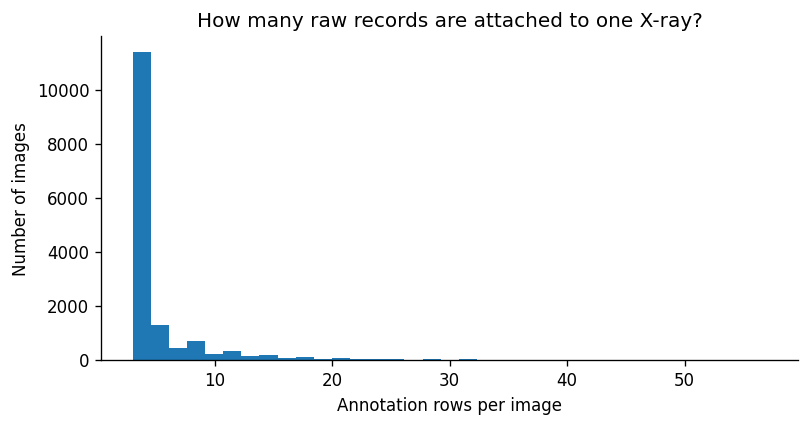

In [30]:
if raw is not None:
    fig, ax = plt.subplots(figsize=(7.5, 3.5))
    ax.hist(annotations_per_image, bins=35)
    ax.set(xlabel="Annotation rows per image", ylabel="Number of images")
    ax.set_title("How many raw records are attached to one X-ray?")
    plt.show()

### 2.14 Are class IDs and class names consistent?

We expect a single class name for each `class_id`. A mismatch could change the interpretation of the label table.

In [31]:
if raw is not None:
    class_dictionary = raw.groupby("class_id")["class_name"].agg(
        names="nunique", example="first")
    display(class_dictionary)
    print("Class IDs with more than one name:", int(class_dictionary.names.gt(1).sum()))

,names,example
class_id,,
0,1,Aortic enlargement
1,1,Atelectasis
2,1,Calcification
3,1,Cardiomegaly
4,1,Consolidation
5,1,ILD
6,1,Infiltration
7,1,Lung Opacity
8,1,Nodule/Mass


Class IDs with more than one name: 0


In [32]:
if raw is not None:
    raw_ids = set(raw.image_id.dropna().astype(str))
    prepared_ids = set(all_labels.image_id.dropna().astype(str))
    print("Raw image IDs missing in prepared splits:", len(raw_ids - prepared_ids))
    print("Prepared image IDs absent from raw annotations:", len(prepared_ids - raw_ids))

Raw image IDs missing in prepared splits: 0
Prepared image IDs absent from raw annotations: 0


In [33]:
if raw is not None:
    missing_coordinates = (
        raw.groupby("class_name")["x_min"]
           .apply(lambda x: int(x.isna().sum()))
           .sort_values(ascending=False)
    )
    display(missing_coordinates.to_frame("missing x_min"))

,missing x_min
class_name,
No finding,31818
Atelectasis,0
Aortic enlargement,0
Cardiomegaly,0
Consolidation,0
ILD,0
Calcification,0
Infiltration,0
Lung Opacity,0


Missing box coordinates associated with *No finding* are part of the annotation schema, not necessarily missing clinical measurements. Counts in the next sections refer to **unique positive images per label**.

## 3. How much does the annotation rule matter?

Each public training X-ray has readings from three radiologists. The project's current image-level targets follow the **union rule**: one positive reader is enough. We compare that with **majority voting** (at least two readers), not to declare one medically correct, but to measure how dependent the target distribution is on the aggregation rule.

A radiologist who drew three boxes of the same category still contributes **one vote** for that category.

In [34]:
if raw is not None:
    reader_count = raw.groupby("image_id").rad_id.nunique()
    display(reader_count.value_counts().sort_index()
            .rename_axis("radiologists per image").to_frame("images"))
else:
    print("Skipped: original radiologist annotations are unavailable.")

,images
radiologists per image,
3,15000


### 3.1 Reader workload across the released annotations

The number of annotated images per reader may differ. This is a descriptive count, not a comparison of radiologist quality.

In [35]:
if raw is not None:
    reader_workload = (raw[["rad_id", "image_id"]].drop_duplicates()
                       .groupby("rad_id").size().sort_values(ascending=False))
    display(reader_workload.rename("distinct images read").to_frame().head(20))

,distinct images read
rad_id,
R8,6582
R10,6467
R9,6125
R2,3119
R5,2783
R3,2285
R6,2041
R1,1995
R7,1733


### 3.2 Count votes per image and abnormality

In [36]:
if raw is not None:
    one_vote_per_reader = (
        raw.loc[raw.class_id.between(0, 13), ["image_id", "rad_id", "class_id"]]
           .drop_duplicates()
    )
    votes = (one_vote_per_reader.groupby(["image_id", "class_id"]).size()
             .unstack(fill_value=0)
             .reindex(index=all_labels.image_id, columns=range(14), fill_value=0))
    votes.columns = DISEASES
    readers = reader_count.reindex(votes.index)
    if readers.isna().any():
        raise ValueError("Some processed image IDs are missing from original annotations")
    display(votes.head())

,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis
image_id,,,,,,,,,,,,,,
000434271f63a053c4128a0ba6352c7f,0,0,0,0,0,0,0,0,0,0,0,0,0,0
00053190460d56c53cc3e57321387478,0,0,0,0,0,0,0,0,0,0,0,0,0,0
0005e8e3701dfb1dd93d53e2ff537b6e,0,0,0,0,1,0,1,2,1,0,0,0,0,0
0007d316f756b3fa0baea2ff514ce945,2,0,0,1,0,1,0,0,0,0,0,3,0,2
000ae00eb3942d27e0b97903dd563a6e,0,0,0,0,0,0,0,0,0,0,0,0,0,0


### 3.3 How many radiologists support each image-level label?

Count **unique radiologists**, not boxes. A label supported by only one of three readers will disappear under majority voting.

In [37]:
if raw is not None:
    vote_strength = pd.DataFrame({
        "1 reader": votes.eq(1).sum(),
        "2 readers": votes.eq(2).sum(),
        "3 readers": votes.ge(3).sum(),
    }).astype(int)
    display(vote_strength.sort_values("1 reader", ascending=False))

,1 reader,2 readers,3 readers
Pleural thickening,1099,517,365
Lung Opacity,775,380,167
Other lesion,772,235,127
Aortic enlargement,721,602,1744
Pulmonary fibrosis,600,384,633
Cardiomegaly,483,520,1297
Nodule/Mass,421,224,181
Pleural effusion,398,195,439
Infiltration,368,154,91
Calcification,275,120,57


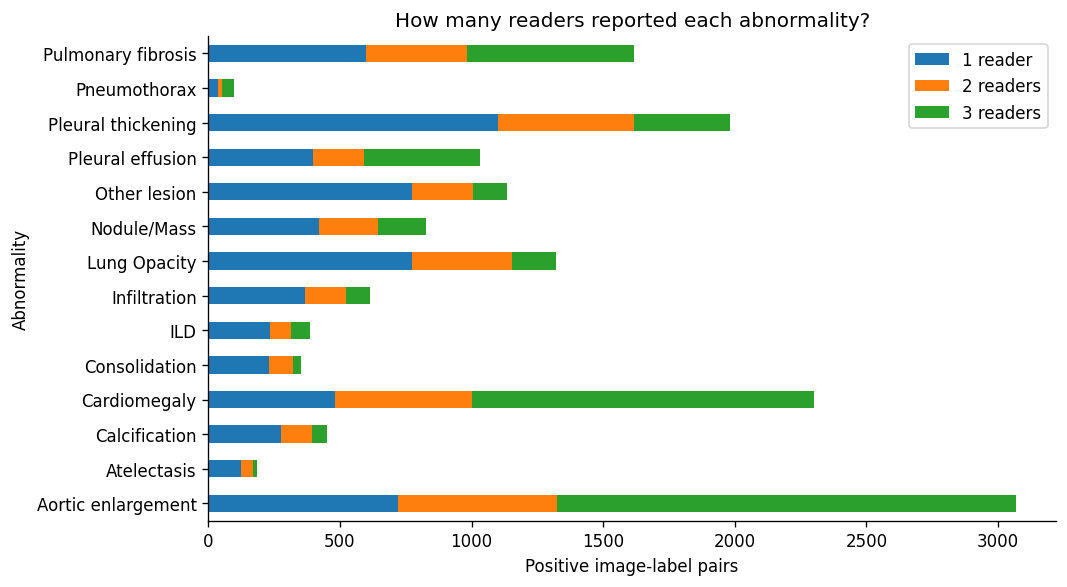

In [38]:
if raw is not None:
    fig, ax = plt.subplots(figsize=(9, 5))
    vote_strength.loc[DISEASES].plot.barh(stacked=True, ax=ax)
    ax.set(xlabel="Positive image-label pairs", ylabel="Abnormality")
    ax.set_title("How many readers reported each abnormality?")
    plt.tight_layout()
    plt.show()

### 3.4 Compare union and majority labels

In [39]:
if raw is not None:
    union = votes.ge(1)
    threshold = np.floor(readers.to_numpy()[:, None] / 2).astype(int) + 1
    majority = pd.DataFrame(votes.to_numpy() >= threshold,
                            index=votes.index, columns=DISEASES)
    audit = pd.DataFrame({
        "union_images": union.sum().astype(int),
        "majority_images": majority.sum().astype(int),
        "one_reader_only_images": votes.eq(1).sum().astype(int),
    })
    audit["lost_if_majority"] = audit.union_images - audit.majority_images
    audit["lost_%_of_union"] = (
        100 * audit.lost_if_majority / audit.union_images.replace(0, np.nan))
    display(audit.sort_values("lost_%_of_union", ascending=False).round(2))
    audit.to_csv(OUTPUT_DIR / "radiologist_voting_sensitivity.csv", index_label="label")

,union_images,majority_images,one_reader_only_images,lost_if_majority,lost_%_of_union
Other lesion,1134,362,772,772,68.08
Atelectasis,186,62,124,124,66.67
Consolidation,353,121,232,232,65.72
Calcification,452,177,275,275,60.84
ILD,386,152,234,234,60.62
Infiltration,613,245,368,368,60.03
Lung Opacity,1322,547,775,775,58.62
Pleural thickening,1981,882,1099,1099,55.48
Nodule/Mass,826,405,421,421,50.97
Pneumothorax,96,58,38,38,39.58


### 3.5 Compare the actual project labels with the reconstructed union labels

The prepared CSVs should agree with the union rule applied to the raw annotation file. We calculate the number of differing image-label entries rather than simply assuming they match.

In [40]:
if raw is not None:
    prepared_union = all_labels.set_index("image_id").loc[union.index, DISEASES].astype(bool)
    unequal = (prepared_union.to_numpy() != union.to_numpy())
    print("Different image-label entries:", int(unequal.sum()))
    print("Images with at least one disagreement:", int(unequal.any(axis=1).sum()))

Different image-label entries: 0
Images with at least one disagreement: 0


In [41]:
if raw is not None:
    print("Images with >= 1 abnormality (union):", int(union.any(axis=1).sum()))
    print("Images with >= 1 abnormality (majority):", int(majority.any(axis=1).sum()))
    print("Changed to No finding:", int((union.any(axis=1) & ~majority.any(axis=1)).sum()))
    print("Reader disagreement is not the same as a confirmed labeling error.")

Images with >= 1 abnormality (union): 4394
Images with >= 1 abnormality (majority): 4352
Changed to No finding: 42
Reader disagreement is not the same as a confirmed labeling error.


### 3.6 Visualize which labels change most

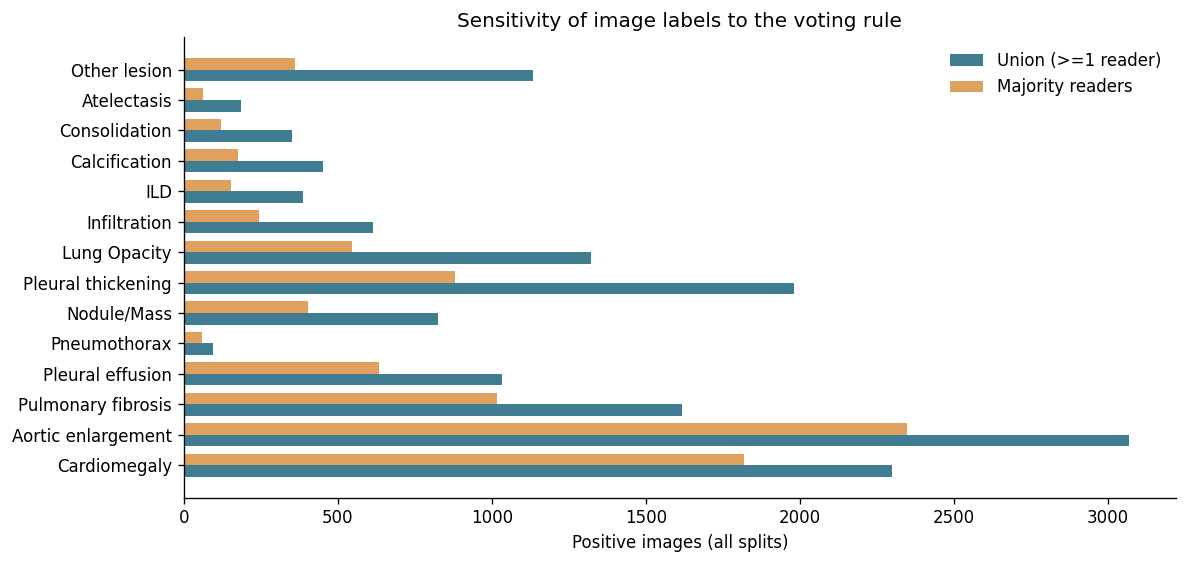

In [42]:
if raw is not None:
    ordered = audit.sort_values("lost_%_of_union")
    fig, ax = plt.subplots(figsize=(10, 4.8))
    y = np.arange(len(ordered))
    ax.barh(y - .19, ordered.union_images, height=.38,
            label="Union (>=1 reader)", color="#407c92")
    ax.barh(y + .19, ordered.majority_images, height=.38,
            label="Majority readers", color="#e0a15e")
    ax.set_yticks(y, ordered.index)
    ax.set_xlabel("Positive images (all splits)")
    ax.set_title("Sensitivity of image labels to the voting rule")
    ax.legend(frameon=False)
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "radiologist_vote_comparison.png", dpi=180)
    plt.show()

 The number of images positive for a particular label can change considerably even if relatively few images lose *all* abnormality labels. These are results about **how labels are constructed**, not an estimate of radiologists' diagnostic accuracy.

## 4. Which labels are common and which are rare?

We now use the **training split only**, because this is the distribution seen during model fitting. For each category, an image counts once if its label is positive, regardless of how many boxes or radiologists recorded it.

### 4.1 Count positive images for each label

In [43]:
counts = train[CLASS_NAMES].sum().astype(int)
prevalence = (100 * counts / len(train)).round(2)
class_stats = pd.DataFrame({
    "positive_train_images": counts,
    "train_prevalence_%": prevalence,
})
display(class_stats.sort_values("positive_train_images", ascending=False))
class_stats.to_csv(OUTPUT_DIR / "class_prevalence_train.csv")

,positive_train_images,train_prevalence_%
No finding,8485,70.76
Aortic enlargement,2454,20.47
Cardiomegaly,1840,15.34
Pleural thickening,1585,13.22
Pulmonary fibrosis,1294,10.79
Lung Opacity,1058,8.82
Other lesion,907,7.56
Pleural effusion,826,6.89
Nodule/Mass,661,5.51
Infiltration,490,4.09


### 4.2 Prevalence among all images versus abnormal images

A percentage can look very different depending on the denominator. This table uses only the subset that has at least one abnormality as the second denominator.

In [44]:
abnormal_train = train.loc[train[NO_FINDING].eq(0)]
conditional_prevalence = pd.DataFrame({
    "positive_images": counts[DISEASES],
    "% all training images": 100 * counts[DISEASES] / len(train),
    "% abnormal training images": 100 * counts[DISEASES] / len(abnormal_train),
}).sort_values("positive_images", ascending=False)
display(conditional_prevalence.round(2).head(14))

,positive_images,% all training images,% abnormal training images
Aortic enlargement,2454,20.47,69.99
Cardiomegaly,1840,15.34,52.48
Pleural thickening,1585,13.22,45.21
Pulmonary fibrosis,1294,10.79,36.91
Lung Opacity,1058,8.82,30.18
Other lesion,907,7.56,25.87
Pleural effusion,826,6.89,23.56
Nodule/Mass,661,5.51,18.85
Infiltration,490,4.09,13.98
Calcification,362,3.02,10.33


### 4.3 Plot the abnormality distribution

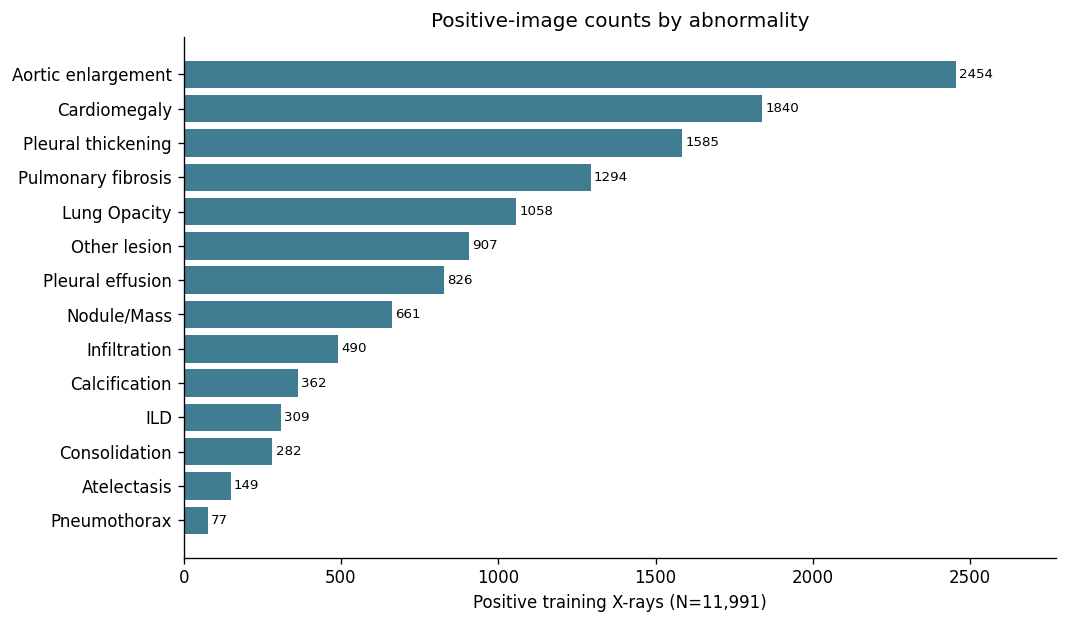

In [45]:
abnormality_counts = counts.loc[DISEASES].sort_values()
fig, ax = plt.subplots(figsize=(9, 5.3))
ax.barh(abnormality_counts.index, abnormality_counts.values, color="#407c92")
ax.set(xlabel=f"Positive training X-rays (N={len(train):,})",
       title="Positive-image counts by abnormality")
for i, value in enumerate(abnormality_counts):
    ax.text(value + 10, i, str(int(value)), va="center", fontsize=8)
ax.set_xlim(0, abnormality_counts.max() * 1.13)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "class_distribution.png", dpi=180)
plt.show()

In [46]:
print(f"No finding: {counts[NO_FINDING]:,} / {len(train):,} "
      f"({100 * counts[NO_FINDING] / len(train):.2f}%)")
print(f"Largest-to-smallest abnormal class count ratio: "
      f"{abnormality_counts.max() / abnormality_counts.min():.1f}")

No finding: 8,485 / 11,991 (70.76%)
Largest-to-smallest abnormal class count ratio: 31.9


### 4.4 A deliberately uninformative baseline

If we always predicted *No finding*, we would match the complete training label vector for every *No finding* image. This simple calculation shows why a high aggregate accuracy need not imply useful abnormality detection.

In [47]:
no_finding_baseline = 100 * train[NO_FINDING].mean()
print(f"Always-No-finding exact-match rate on TRAIN labels: {no_finding_baseline:.2f}%")
print("This is not a trained model, nor a per-class recall or ROC-AUC result.")

Always-No-finding exact-match rate on TRAIN labels: 70.76%
This is not a trained model, nor a per-class recall or ROC-AUC result.


## 5. How many abnormalities appear on the same X-ray?

Class prevalence does not show how the labels combine. To describe the structure of the classification problem, we count the positive **abnormality** labels on each training image; *No finding* does not count as an abnormality.

### 5.1 Compute label cardinality

In [48]:
cardinality = train[DISEASES].sum(axis=1)
cardinality_table = cardinality.value_counts().sort_index().rename("images")
display(cardinality_table.to_frame())
cardinality_table.to_csv(OUTPUT_DIR / "label_cardinality_train.csv")

,images
0,8485
1,253
2,943
3,786
4,622
5,426
6,253
7,146
8,58
9,15


### 5.2 Inspect examples at different levels of label cardinality

We do not infer the actual clinical situation from these labels. Here we only check that the multi-hot combinations look reasonable.

In [49]:
for n_labels in [0, 1, 2, 5]:
    examples = train.loc[cardinality.eq(n_labels), ["image_id", *CLASS_NAMES]].head(2)
    print(f"Examples with {n_labels} abnormality labels:")
    display(examples)

Examples with 0 abnormality labels:


,image_id,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding
0,000434271f63a053c4128a0ba6352c7f,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,00053190460d56c53cc3e57321387478,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


Examples with 1 abnormality labels:


,image_id,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding
50,011244ab511b20130d846f5f8f0c3866,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
68,0187da5fd71c7a2917346bf12a67bbe4,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


Examples with 2 abnormality labels:


,image_id,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding
8,001d127bad87592efe45a5c7678f8b8d,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0
21,00675cd546313f912cadd4ad54415d69,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0


Examples with 5 abnormality labels:


,image_id,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding
3,0007d316f756b3fa0baea2ff514ce945,1,0,0,1,0,1,0,0,0,0,0,1,0,1,0
5,000d68e42b71d3eac10ccc077aba07c1,1,0,0,0,0,0,0,1,0,1,0,1,0,1,0


In [50]:
abnormal_images = int(cardinality.gt(0).sum())
multi_labeled_images = int(cardinality.ge(2).sum())
print(f"At least two abnormalities / all images: "
      f"{100 * multi_labeled_images / len(train):.2f}%")
print(f"At least two abnormalities / abnormal images: "
      f"{100 * multi_labeled_images / abnormal_images:.2f}%")

At least two abnormalities / all images: 27.13%
At least two abnormalities / abnormal images: 92.78%


### 5.3 Visualize how label counts are distributed

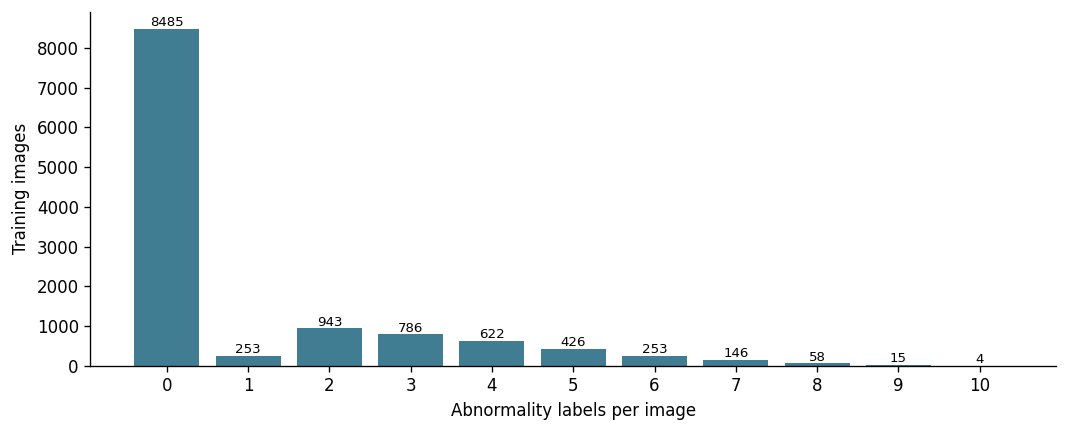

In [51]:
fig, ax = plt.subplots(figsize=(9, 3.7))
ax.bar(cardinality_table.index, cardinality_table.values, color="#407c92")
for x, y in cardinality_table.items():
    ax.text(x, y + 65, str(int(y)), ha="center", fontsize=8)
ax.set(xlabel="Abnormality labels per image",
       ylabel="Training images",
       xticks=cardinality_table.index)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "label_cardinality.png", dpi=180)
plt.show()

**Interpretation.** We report multi-label rates using both denominators: all training images and images with at least one abnormality. The union rule may increase the number of labels per image because findings from different readers are combined.

## 6. Which abnormalities tend to appear together?

A heatmap can reveal relationships, but it does not tell us whether a large score is based on many images or only a handful. We therefore calculate **joint counts**, **Jaccard similarity**, **conditional probabilities**, and **lift**.

- Jaccard(A,B) = n(A and B) / n(A or B)
- P(B|A) = n(A and B) / n(A)
- Lift(A,B) = P(A and B) / (P(A) × P(B))

These describe **annotation-level statistical associations**, not causal medical relationships.

### 6.1 Count how often pairs of labels occur together

In [52]:
binary = train[DISEASES].astype(int)
cooccurrence = binary.T.dot(binary)
display(cooccurrence.iloc[:7, :7])

,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration
Aortic enlargement,2454,64,249,1582,121,193,239
Atelectasis,64,149,25,32,48,20,38
Calcification,249,25,362,142,19,41,27
Cardiomegaly,1582,32,142,1840,83,101,146
Consolidation,121,48,19,83,282,28,111
ILD,193,20,41,101,28,309,108
Infiltration,239,38,27,146,111,108,490


### 6.2 Compare Jaccard, conditional probabilities and lift

In [53]:
pair_records = []
N = len(train)
for label_a, label_b in combinations(DISEASES, 2):
    na, nb = int(counts[label_a]), int(counts[label_b])
    both = int(cooccurrence.loc[label_a, label_b])
    either = na + nb - both
    pair_records.append({
        "label_A": label_a, "label_B": label_b, "both_images": both,
        "A_images": na, "B_images": nb,
        "jaccard": both / either if either else np.nan,
        "P_B_given_A_%": 100 * both / na if na else np.nan,
        "P_A_given_B_%": 100 * both / nb if nb else np.nan,
        "lift": both * N / (na * nb) if na * nb else np.nan,
    })
pairs = pd.DataFrame(pair_records)
pairs.to_csv(OUTPUT_DIR / "cooccurrence_all_pairs.csv", index=False)

In [54]:
print("Top pairs by Jaccard")
display(pairs.nlargest(10, "jaccard").round(3))

Top pairs by Jaccard


,label_A,label_B,both_images,A_images,B_images,jaccard,P_B_given_A_%,P_A_given_B_%,lift
2,Aortic enlargement,Cardiomegaly,1582,2454,1840,0.583,64.466,85.978,4.201
85,Pleural effusion,Pleural thickening,670,826,1585,0.385,81.114,42.271,6.137
10,Aortic enlargement,Pleural thickening,1075,2454,1585,0.363,43.806,67.823,3.314
89,Pleural thickening,Pulmonary fibrosis,758,1585,1294,0.357,47.823,58.578,4.432
72,Lung Opacity,Pleural effusion,436,1058,826,0.301,41.210,52.785,5.982
75,Lung Opacity,Pulmonary fibrosis,544,1058,1294,0.301,51.418,42.040,4.765
73,Lung Opacity,Pleural thickening,572,1058,1585,0.276,54.064,36.088,4.090
12,Aortic enlargement,Pulmonary fibrosis,756,2454,1294,0.253,30.807,58.423,2.855
43,Cardiomegaly,Pleural thickening,688,1840,1585,0.251,37.391,43.407,2.829
82,Other lesion,Pleural thickening,494,907,1585,0.247,54.465,31.167,4.120


In [55]:
print("Top pairs by lift (at least 30 co-positive images)")
display(pairs.query("both_images >= 30").nlargest(10, "lift").round(3))

Top pairs by lift (at least 30 co-positive images)


,label_A,label_B,both_images,A_images,B_images,jaccard,P_B_given_A_%,P_A_given_B_%,lift
15,Atelectasis,Consolidation,48,149,282,0.125,32.215,17.021,13.698
48,Consolidation,Lung Opacity,241,282,1058,0.219,85.461,22.779,9.686
47,Consolidation,Infiltration,111,282,490,0.168,39.362,22.653,9.632
86,Pleural effusion,Pneumothorax,49,826,77,0.057,5.932,63.636,9.238
55,ILD,Infiltration,108,309,490,0.156,34.951,22.041,8.553
51,Consolidation,Pleural effusion,156,282,826,0.164,55.319,18.886,8.031
30,Calcification,Nodule/Mass,148,362,661,0.169,40.884,22.390,7.417
63,Infiltration,Lung Opacity,300,490,1058,0.240,61.224,28.355,6.939
49,Consolidation,Nodule/Mass,102,282,661,0.121,36.170,15.431,6.562
24,Atelectasis,Pulmonary fibrosis,104,149,1294,0.078,69.799,8.037,6.468


### 6.3 See the relationships in a heatmap

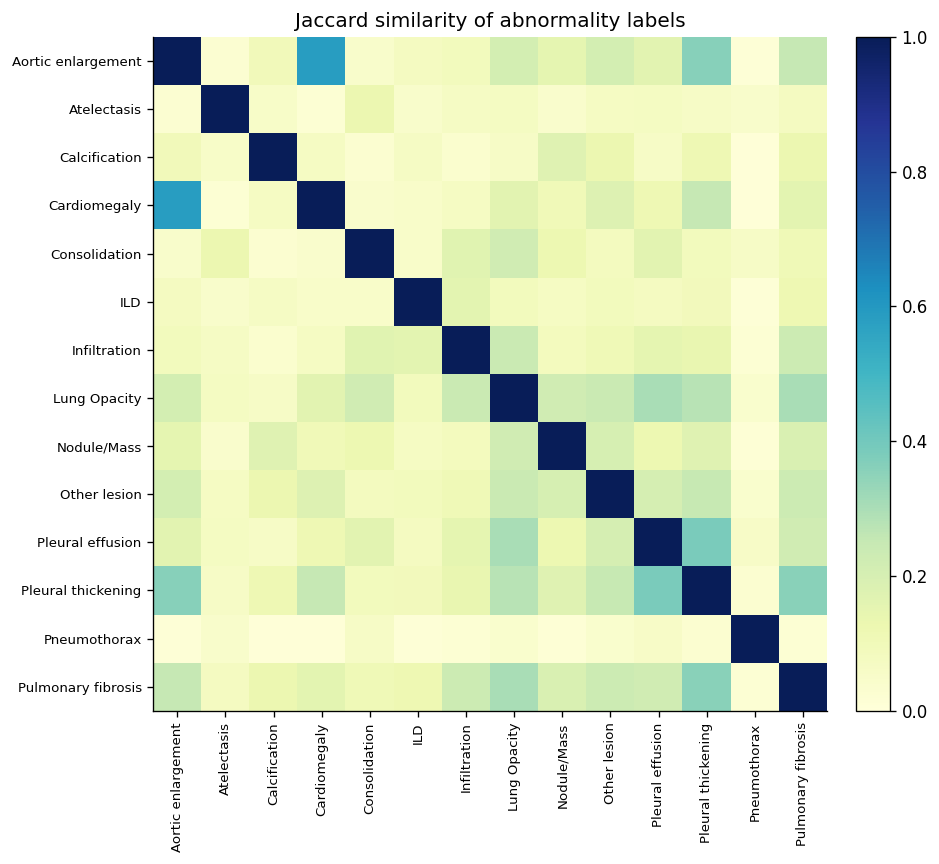

In [56]:
jaccard_matrix = cooccurrence.astype(float).copy()
for a in DISEASES:
    for b in DISEASES:
        denominator = counts[a] + counts[b] - cooccurrence.loc[a, b]
        jaccard_matrix.loc[a, b] = (
            cooccurrence.loc[a, b] / denominator if denominator else np.nan
        )
fig, ax = plt.subplots(figsize=(9, 7.3))
im = ax.imshow(jaccard_matrix.to_numpy(), cmap="YlGnBu", vmin=0, vmax=1)
ax.set_xticks(np.arange(14), DISEASES, rotation=90, fontsize=8)
ax.set_yticks(np.arange(14), DISEASES, fontsize=8)
ax.set_title("Jaccard similarity of abnormality labels")
fig.colorbar(im, ax=ax, fraction=.035, pad=.03)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "jaccard_heatmap.png", dpi=190)
plt.show()

### 6.4 Focus on the strongest co-occurring pairs

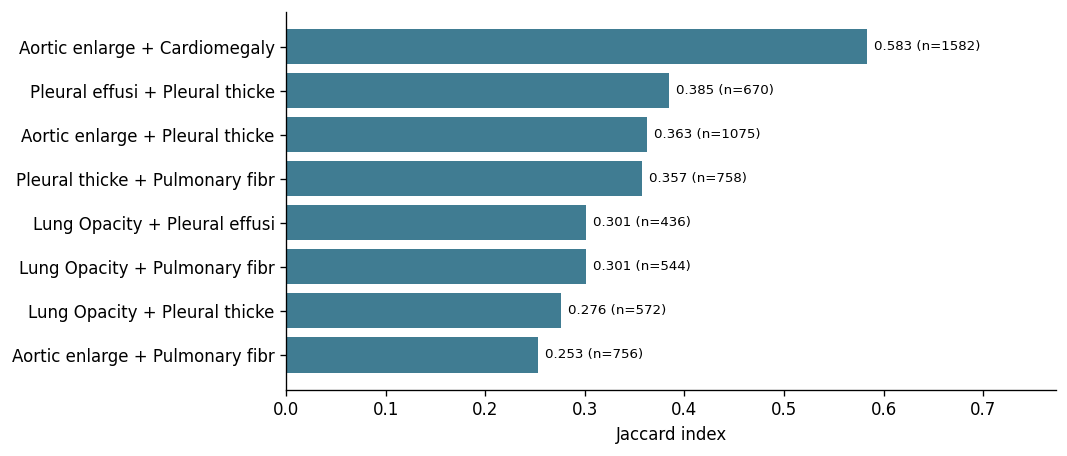

In [57]:
top_pairs = pairs.nlargest(8, "jaccard").sort_values("jaccard")
pair_labels = (top_pairs.label_A.str.slice(0, 14) + " + "
               + top_pairs.label_B.str.slice(0, 14))
fig, ax = plt.subplots(figsize=(9, 3.9))
ax.barh(pair_labels, top_pairs.jaccard, color="#407c92")
for i, (score, n) in enumerate(zip(top_pairs.jaccard, top_pairs.both_images)):
    ax.text(score + .007, i, f"{score:.3f} (n={n})",
            fontsize=8, va="center")
ax.set_xlim(0, min(1., top_pairs.jaccard.max() + .19))
ax.set_xlabel("Jaccard index")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "top_label_pairs.png", dpi=180)
plt.show()

Jaccard emphasizes overlap relative to union size; lift compares joint prevalence with an independence baseline. High lift from very low support can be unstable, so we only rank lift for pairs with at least 30 joint positive images.

## 7. Are train, validation and test similarly distributed?

The preparation script uses multi-label stratification at the **image** level. We compare the positive counts and prevalence across splits, then examine how few positive test cases can make rare-label recall sensitive to one prediction.

### 7.1 Positive counts by split

In [58]:
split_counts = pd.DataFrame({
    part: frame[CLASS_NAMES].sum().astype(int)
    for part, frame in frames.items()
})
split_prevalence = pd.DataFrame({
    part: 100 * frame[CLASS_NAMES].mean()
    for part, frame in frames.items()
})
display(split_counts)
split_counts.to_csv(OUTPUT_DIR / "split_class_support.csv")

,train,val,test
Aortic enlargement,2454,306,307
Atelectasis,149,18,19
Calcification,362,45,45
Cardiomegaly,1840,230,230
Consolidation,282,35,36
ILD,309,38,39
Infiltration,490,61,62
Lung Opacity,1058,132,132
Nodule/Mass,661,82,83
Other lesion,907,113,114


### 7.2 Class support in the smallest split

Even when percentages are similar, some classes may have too few positive test cases for stable per-class metrics.

In [59]:
small_support = split_counts.loc[DISEASES].sort_values("test").head(7)
display(small_support)

,train,val,test
Pneumothorax,77,9,10
Atelectasis,149,18,19
Consolidation,282,35,36
ILD,309,38,39
Calcification,362,45,45
Infiltration,490,61,62
Nodule/Mass,661,82,83


In [60]:
difference = (split_prevalence[["val", "test"]]
              .sub(split_prevalence["train"], axis=0).abs())
print("Largest difference from training prevalence (percentage points)")
print(difference.max().round(3))

Largest difference from training prevalence (percentage points)
val     0.427
test    0.959
dtype: float64


### 7.3 Compare prevalence in one figure

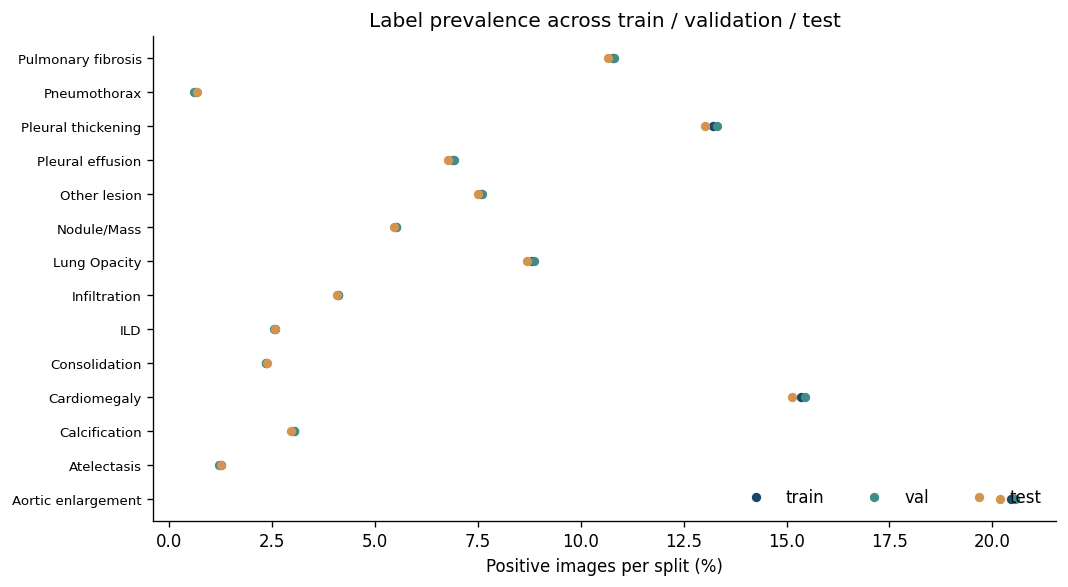

In [61]:
fig, ax = plt.subplots(figsize=(9, 5))
for part, color in [("train", "#1a4667"), ("val", "#408c89"),
                    ("test", "#d3944f")]:
    ax.scatter(split_prevalence[part].loc[DISEASES],
               np.arange(len(DISEASES)), label=part, color=color, s=21, zorder=3)
ax.set_yticks(np.arange(len(DISEASES)), DISEASES, fontsize=8)
ax.set(xlabel="Positive images per split (%)",
       title="Label prevalence across train / validation / test")
ax.legend(frameon=False, ncol=3, loc="lower right")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "split_prevalence.png", dpi=180)
plt.show()

### 7.4 What does one true positive mean for a rare class?

In [62]:
test_support = split_counts.loc[DISEASES, "test"]
recall_sensitivity = pd.DataFrame({
    "test_positive": test_support,
    "one_extra_TP_recall_change_pp": 100 / test_support.replace(0, np.nan),
})
display(recall_sensitivity.sort_values("test_positive").head(8).round(2))

,test_positive,one_extra_TP_recall_change_pp
Pneumothorax,10,10.00
Atelectasis,19,5.26
Consolidation,36,2.78
ILD,39,2.56
Calcification,45,2.22
Infiltration,62,1.61
Nodule/Mass,83,1.20
Pleural effusion,103,0.97


**Interpretation.** Similar label prevalence is useful for model comparison but does not prove patient-level independence. A test class represented by only ten positive images changes its recall by ten percentage points for each additional correctly identified positive case.

## 8. Is the split technically consistent?

Before interpreting model performance, we can verify that no **image ID** appears in more than one split and that every CSV record points to a PNG file. An additional byte-level hash check screens for identical PNG files.

These checks do **not** establish independence between patients: the released data do not provide a validated, stable patient identifier for grouping the images.

### 8.1 Check image ID overlap

In [63]:
split_ids = {part: set(df.image_id.astype(str)) for part, df in frames.items()}
for left, right in combinations(split_ids, 2):
    print(f"{left} vs {right}: "
          f"{len(split_ids[left] & split_ids[right])} shared image IDs")

train vs val: 0 shared image IDs
train vs test: 0 shared image IDs
val vs test: 0 shared image IDs


### 8.2 Also look for duplicate IDs across the combined split table

This gives a direct view of any offending records, rather than only reporting intersection sizes.

In [64]:
reused_ids = all_labels.loc[all_labels.duplicated("image_id", keep=False)]
print("Rows whose image ID also appears elsewhere:", len(reused_ids))
display(reused_ids.head(10))

Rows whose image ID also appears elsewhere: 0


,image_id,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding


### 8.3 Verify that PNG files and label records match

In [65]:
image_paths = {
    (part, uid): DATA_DIR / part / "images" / f"{uid}.png"
    for part, df in frames.items()
    for uid in df.image_id.astype(str)
}
missing_files = [key for key, path in image_paths.items() if not path.is_file()]
print("Missing PNG files referenced in CSV:", len(missing_files))
if missing_files:
    raise FileNotFoundError(f"First missing image: {missing_files[0]}")

unreferenced = {
    part: len({path.stem for path in (DATA_DIR / part / "images").glob("*.png")}
              - split_ids[part])
    for part in frames
}
print("Unreferenced PNGs by split:", unreferenced)

Missing PNG files referenced in CSV: 0
Unreferenced PNGs by split: {'train': 0, 'val': 0, 'test': 0}


### 8.4 Check the file-name extension and folder counts

The CSV and image directories should agree not only on paths, but also on the number of PNG files in each split.

In [66]:
folder_audit = []
for part, df in frames.items():
    folder = DATA_DIR / part / "images"
    png_files = list(folder.glob("*.png"))
    folder_audit.append({"split": part, "csv_rows": len(df), "png_files": len(png_files),
                         "other_files": sum(p.is_file() and p.suffix.lower() != ".png"
                                            for p in folder.iterdir())})
display(pd.DataFrame(folder_audit))

,split,csv_rows,png_files,other_files
0,train,11991,11991,0
1,val,1489,1489,0
2,test,1520,1520,0


### 8.5 Search for byte-identical PNG files

The default calculation covers all prepared PNGs. SHA-256 finds files with identical bytes; it does not identify different views of the same patient or resized versions of the same image.

In [67]:
def sha256sum(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

In [68]:
file_records = list(image_paths.items())
rng = np.random.default_rng(SEED)
selected = file_records if RUN_FULL_SHA256 else [
    file_records[i] for i in rng.choice(
        len(file_records), size=min(450, len(file_records)), replace=False)
]
print(f"Checking {len(selected):,} / {len(file_records):,} images")

Checking 15,000 / 15,000 images


In [69]:
hashes = pd.DataFrame([
    {"split": key[0], "image_id": key[1], "digest": sha256sum(path)}
    for key, path in selected
])
print("Files hashed:", len(hashes))

Files hashed: 15000


In [70]:
hash_groups = hashes.groupby("digest").agg(
    file_count=("image_id", "size"),
    split_count=("split", "nunique"),
)
print("Duplicate groups (within any split):", int(hash_groups.file_count.gt(1).sum()))
print("Identical-file groups crossing splits:", int(hash_groups.split_count.gt(1).sum()))
display(hash_groups.query("file_count > 1").head(10))

Duplicate groups (within any split): 1
Identical-file groups crossing splits: 0


,file_count,split_count
digest,,
cd787be61a7dda1731309f34109f3d757914895eebd684ac1ad2ea4421cffbbc,2,1


In [89]:
duplicates = hashes[
    hashes.duplicated(subset="digest", keep=False)
].sort_values("digest")

display(duplicates)

all_labels = pd.concat(
    [df.assign(split=split) for split, df in frames.items()],
    ignore_index=True
)

duplicate_details = duplicates.merge(
    all_labels,
    on=["split", "image_id"],
    how="left"
)

display(
    duplicate_details[
        ["split", "image_id", "digest"] + CLASS_NAMES
    ]
)

,split,image_id,digest
7003,train,94887c081f4be59d246c59170d05dfc6,cd787be61a7dda1731309f34109f3d757914895eebd684...
10467,train,ddbe41935f4c7c4c6624654585e12652,cd787be61a7dda1731309f34109f3d757914895eebd684...


,split,image_id,digest,Aortic enlargement,Atelectasis,Calcification,Cardiomegaly,Consolidation,ILD,Infiltration,Lung Opacity,Nodule/Mass,Other lesion,Pleural effusion,Pleural thickening,Pneumothorax,Pulmonary fibrosis,No finding
0,train,94887c081f4be59d246c59170d05dfc6,cd787be61a7dda1731309f34109f3d757914895eebd684...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
1,train,ddbe41935f4c7c4c6624654585e12652,cd787be61a7dda1731309f34109f3d757914895eebd684...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


Two training images have identical PNG content and the same No finding label despite having different image IDs. This introduces one redundant sample (approximately 0.0083% of the training set). Given its small proportion, the impact is expected to be limited, although this has not been experimentally verified. The original dataset is retained for consistency with the model training experiments.

## 9. What do the prepared X-rays look like?

All training inputs are grayscale PNGs standardized to 224 × 224 pixels. We take a reproducible sample from each split to examine overall pixel intensity and contrast, and view representative images with selected image-level labels.

Pixel mean and standard deviation are **descriptive proxies**, not clinical image-quality scores.

### 9.1 Select images for intensity analysis

In [71]:
rng = np.random.default_rng(SEED)
sample_records = []
for part, df in frames.items():
    chosen = rng.choice(
        len(df), size=min(IMAGE_SAMPLE_PER_SPLIT, len(df)), replace=False
    )
    for i in chosen:
        uid = str(df.iloc[i].image_id)
        path = DATA_DIR / part / "images" / f"{uid}.png"
        with Image.open(path) as image:
            pixels = np.asarray(image.convert("L"), dtype=np.float32)
            sample_records.append({
                "split": part, "image_id": uid,
                "width": image.width, "height": image.height,
                "mean_pixel": pixels.mean(), "std_pixel": pixels.std(),
                "dark_fraction": (pixels <= 5).mean(),
            })
quality = pd.DataFrame(sample_records)
print("Sampled images:", len(quality))

Sampled images: 150


### 9.2 Inspect PNG modes, sizes and pixel ranges in the image sample

The sample should contain the expected 8-bit grayscale PNGs. We inspect rather than assume that every file has the same mode and size.

In [72]:
image_metadata = []
for record in sample_records:
    path = image_paths[(record["split"], record["image_id"])]
    with Image.open(path) as im:
        image_metadata.append({
            "split": record["split"], "mode": im.mode,
            "width": im.width, "height": im.height, "format": im.format
        })
metadata_sample = pd.DataFrame(image_metadata)
display(metadata_sample.groupby(["split", "mode", "width", "height", "format"])
        .size().rename("images").reset_index())

,split,mode,width,height,format,images
0,test,L,224,224,PNG,50
1,train,L,224,224,PNG,50
2,val,L,224,224,PNG,50


### 9.3 Look at unusual intensities before plotting averages

Very dark or low-contrast files are candidates for visual inspection, not automatically corrupted images.

In [73]:
display(quality.sort_values("mean_pixel").head(5)[
    ["split", "image_id", "mean_pixel", "std_pixel", "dark_fraction"]])

,split,image_id,mean_pixel,std_pixel,dark_fraction
64,val,ed7e3e636baeaf7967c913d46dbdc2e6,111.911568,76.018539,0.179090
85,val,541ffcf7a179ec5aeef096ceb750e640,113.299644,73.424950,0.167710
24,train,a3411581087b63a70a2bdba24e55ff4e,117.612640,67.112274,0.035854
27,train,b7f4de6bfb8556aed14a15d7c8b38603,119.034180,84.564468,0.199139
20,train,d233017534707d09cf6d9b8c34b3ab10,119.451408,80.320549,0.113002


In [74]:
display(quality.sort_values("std_pixel").head(5)[
    ["split", "image_id", "mean_pixel", "std_pixel", "dark_fraction"]])

,split,image_id,mean_pixel,std_pixel,dark_fraction
23,train,47a50643e0ffee2204984ca1ac6bccf0,192.394547,48.191998,0.017080
114,test,cbd3795d8dca2bad59a3dd16dca46695,174.779099,50.227737,0.014967
12,train,d38141932d16e6729db676b625c1f1d4,178.524948,52.983578,0.013233
56,val,8056906397ecb008b90079dd52617a76,172.553207,54.633411,0.005700
90,val,75e726f1b8f916a9e805f1f1e326a02d,188.313461,54.832527,0.027982


### 9.4 Summarize intensity within each split

In [75]:
intensity_summary = (
    quality.groupby("split")[["mean_pixel", "std_pixel"]]
           .agg(["count", "median", "min", "max"])
           .round(2)
)
display(intensity_summary)

mean_pixel                                     std_pixel             \
           count      median         min         max     count     median   
split                                                                       
test          50  159.529999  120.279999  179.580002        50  70.220001   
train         50  153.279999  117.610001  192.389999        50  70.430000   
val           50  154.330002  111.910004  188.309998        50  70.330002   

                             
             min        max  
split                        
test   50.230000  86.160004  
train  48.189999  86.089996  
val    54.630001  89.680000

### 9.5 Plot the sample distributions

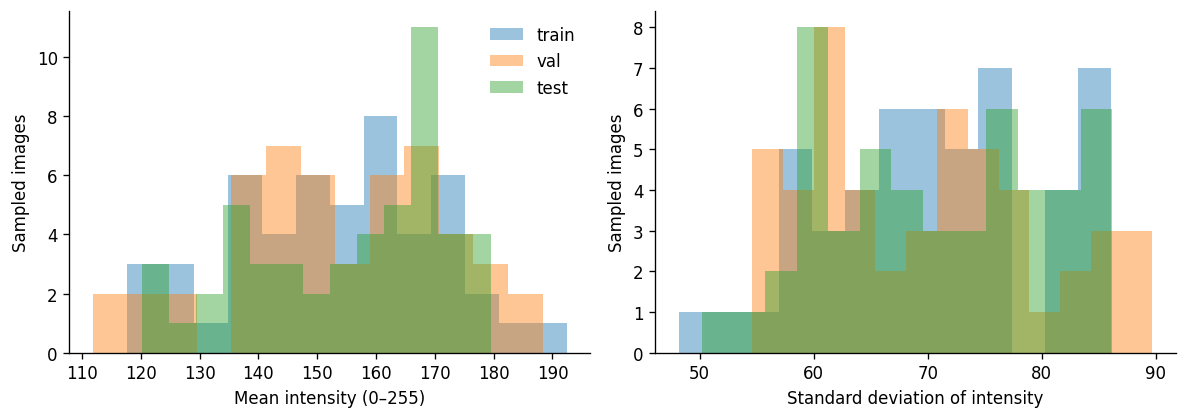

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, column, name in [
    (axes[0], "mean_pixel", "Mean intensity (0–255)"),
    (axes[1], "std_pixel", "Standard deviation of intensity"),
]:
    for split in ("train", "val", "test"):
        ax.hist(quality.loc[quality.split == split, column],
                bins=13, alpha=.44, label=split)
    ax.set_xlabel(name)
    ax.set_ylabel("Sampled images")
axes[0].legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "image_intensity_sample.png", dpi=180)
plt.show()

 The training, validation, and test samples show similar brightness and contrast distributions, with no obvious distribution shift. However, the sample size (50 images per split) is too small to draw conclusions about the entire dataset.

### 9.6 View a few labeled X-rays

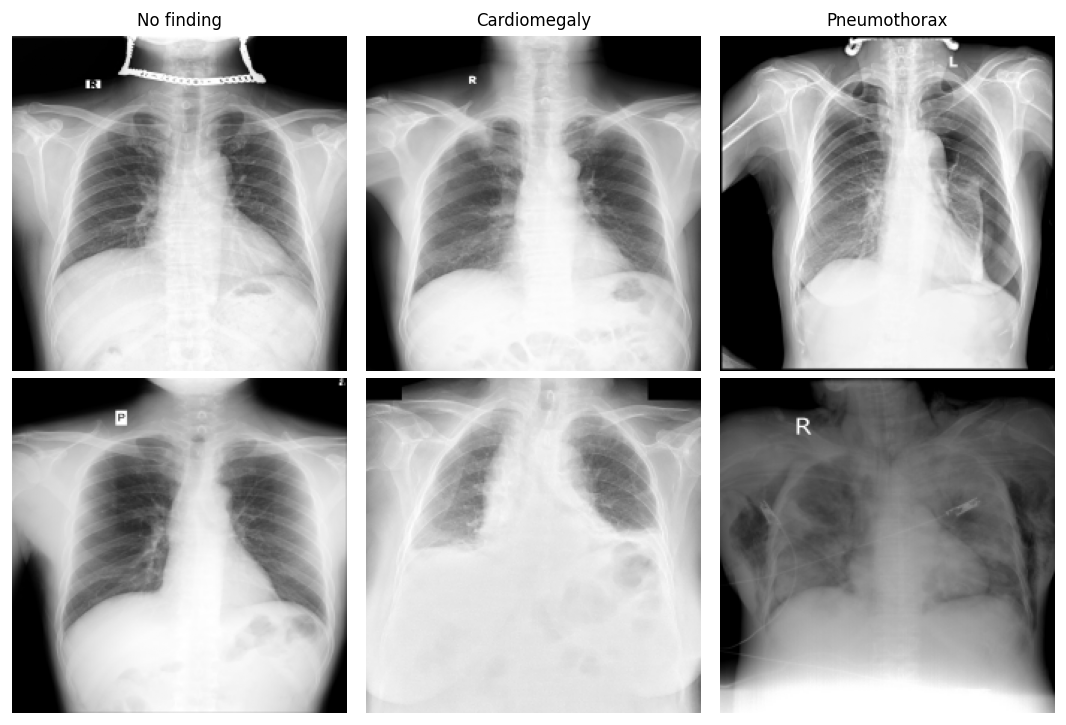

In [77]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6.1))
for j, label in enumerate([NO_FINDING, "Cardiomegaly", "Pneumothorax"]):
    examples = train.loc[train[label].eq(1)].head(2)
    for i in range(2):
        axes[i, j].axis("off")
    for i, (_, record) in enumerate(examples.iterrows()):
        path = DATA_DIR / "train" / "images" / f"{record.image_id}.png"
        with Image.open(path) as image:
            axes[i, j].imshow(image.convert("L"), cmap="gray")
        axes[i, j].set_title(label if i == 0 else "", fontsize=10)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "representative_xrays.png", dpi=180)
plt.show()

These examples illustrate the assigned labels; they have not been independently re-reviewed by clinicians. Intensity statistics based on a sample must not be presented as verified properties of all 15,000 images.

## 10. How small do annotated regions become at 224 × 224?

The original annotations contain bounding boxes expressed in coordinates of the **original DICOM image**. Raw pixel areas are not comparable across studies with different dimensions.

For a DICOM with width `W` and height `H`, we project a box to 224 × 224 using:

- projected width = 224 × (x_max − x_min) / W
- projected height = 224 × (y_max − y_min) / H

This geometric projection measures **region size**, not whether a disease becomes undetectable.

### 10.1 Check annotation geometry

In [78]:
boxes = None
if raw is None:
    print("Skipped: raw annotations are unavailable.")
else:
    boxes = raw.loc[raw.class_id.between(0, 13)].copy()
    for column in ["x_min", "x_max", "y_min", "y_max"]:
        boxes[column] = pd.to_numeric(boxes[column], errors="coerce")
    invalid_coords = boxes[["x_min", "x_max", "y_min", "y_max"]].isna().any(axis=1)
    print("Abnormality annotations with missing coordinates:", int(invalid_coords.sum()))
    boxes = boxes.loc[~invalid_coords].copy()
    invalid_geometry = (boxes.x_max <= boxes.x_min) | (boxes.y_max <= boxes.y_min)
    print("Invalid bounding-box geometry:", int(invalid_geometry.sum()))
    boxes = boxes.loc[~invalid_geometry].copy()

Abnormality annotations with missing coordinates: 0
Invalid bounding-box geometry: 0


### 10.2 Check box duplication, separately from geometry

A repeated annotation row may be a data issue, while multiple legitimate boxes from the same reader can describe separate image regions.

In [79]:
if boxes is not None:
    bbox_key = ["image_id", "rad_id", "class_id", "x_min", "y_min", "x_max", "y_max"]
    print("Identical bounding-box rows:", int(boxes.duplicated(subset=bbox_key).sum()))
    display(boxes.loc[boxes.duplicated(bbox_key, keep=False), bbox_key].head(8))

Identical bounding-box rows: 0


,image_id,rad_id,class_id,x_min,y_min,x_max,y_max


### 10.3 Examine box dimensions in original image coordinates

In [80]:
if boxes is not None:
    boxes["bbox_width_raw"] = boxes.x_max - boxes.x_min
    boxes["bbox_height_raw"] = boxes.y_max - boxes.y_min
    boxes["bbox_area_raw"] = boxes.bbox_width_raw * boxes.bbox_height_raw
    display(boxes[["bbox_width_raw", "bbox_height_raw", "bbox_area_raw"]]
            .describe(percentiles=[.1, .5, .9]).round(1))

,bbox_width_raw,bbox_height_raw,bbox_area_raw
count,36096.0,36096.0,36096.0
mean,440.9,391.4,218415.7
std,332.8,328.1,289379.8
min,11.0,3.0,180.0
10%,109.0,95.0,12706.0
50%,323.0,320.0,106471.0
90%,1006.0,758.0,535051.5
max,2938.0,2803.0,4575318.0


### 10.4 Read original DICOM dimensions

In [81]:
headers = pd.DataFrame(columns=["image_id", "W", "H"])
if boxes is None or DICOM_ZIP is None or not DICOM_ZIP.is_file():
    print("Skipped: raw boxes and/or the DICOM archive are not available.")
else:
    try:
        import pydicom
        with zipfile.ZipFile(DICOM_ZIP) as archive:
            members = {
                Path(name).stem: name for name in archive.namelist()
                if name.lower().endswith(".dicom")
            }
            eligible_ids = sorted(set(boxes.image_id.astype(str)) & set(members))
            if not eligible_ids:
                print("No matching DICOM members were found in the archive.")
            else:
                rng = np.random.default_rng(SEED)
                chosen_ids = rng.choice(
                    eligible_ids,
                    size=min(DICOM_HEADER_SAMPLE, len(eligible_ids)),
                    replace=False
                )
                records = []
                for uid in chosen_ids:
                    with archive.open(members[uid]) as stream:
                        ds = pydicom.dcmread(
                            stream, stop_before_pixels=True,
                            specific_tags=["Rows", "Columns"]
                        )
                    records.append({
                        "image_id": uid, "W": int(ds.Columns), "H": int(ds.Rows)
                    })
                headers = pd.DataFrame(records)
    except ImportError:
        print("pydicom is required: pip install pydicom")
    except Exception as exc:
        print(f"Could not read DICOM headers: {type(exc).__name__}: {exc}")
print("DICOM images sampled:", len(headers))

DICOM images sampled: 60


### 10.5 Project bounding boxes into the resized coordinate system

In [82]:
scaled = pd.DataFrame()
if boxes is not None and not headers.empty:
    scaled = boxes.merge(headers, on="image_id", how="inner")
    scaled["width_224"] = 224 * scaled.bbox_width_raw / scaled.W
    scaled["height_224"] = 224 * scaled.bbox_height_raw / scaled.H
    scaled["short_side_224"] = scaled[["width_224", "height_224"]].min(axis=1)
    scaled["area_fraction"] = scaled.bbox_area_raw / (scaled.W * scaled.H)
    print(f"Projected boxes: {len(scaled)} from {scaled.image_id.nunique()} DICOM images")
    display(scaled[["width_224", "height_224", "short_side_224", "area_fraction"]]
            .describe(percentiles=[.1, .25, .5, .75, .9]).round(3))
else:
    print("Skipped: bounding boxes and DICOM sizes are both required.")

Projected boxes: 492 from 60 DICOM images


,width_224,height_224,short_side_224,area_fraction
count,492.000,492.000,492.000,492.000
mean,38.388,29.099,23.675,0.028
std,32.040,22.119,15.157,0.032
min,3.263,2.509,2.509,0.000
10%,8.179,5.471,5.211,0.001
25%,16.971,11.667,10.137,0.004
50%,26.226,24.635,22.109,0.013
75%,49.787,37.145,32.476,0.049
90%,97.686,61.301,45.060,0.071
max,120.750,136.390,76.252,0.176


### 10.6 Check sampled boxes against image boundaries

In [83]:
if not scaled.empty:
    outside = ((scaled.x_min < 0) | (scaled.y_min < 0) |
               (scaled.x_max > scaled.W) | (scaled.y_max > scaled.H))
    print("Boxes outside sampled image boundaries:", int(outside.sum()), "/", len(scaled))
    display(scaled.loc[outside, ["image_id", "class_id", "W", "H",
                                  "x_min", "y_min", "x_max", "y_max"]].head(10))

Boxes outside sampled image boundaries: 0 / 492


,image_id,class_id,W,H,x_min,y_min,x_max,y_max


### 10.7 Which projected regions are only a few pixels wide?

In [84]:
if not scaled.empty:
    for threshold in (4, 8, 16):
        count = int((scaled.short_side_224 < threshold).sum())
        print(f"Shorter side < {threshold}px: {count}/{len(scaled)} "
              f"({100 * count / len(scaled):.1f}%; sampled boxes)")

Shorter side < 4px: 22/492 (4.5%; sampled boxes)
Shorter side < 8px: 82/492 (16.7%; sampled boxes)
Shorter side < 16px: 172/492 (35.0%; sampled boxes)


### 10.8 View projected short-side dimensions

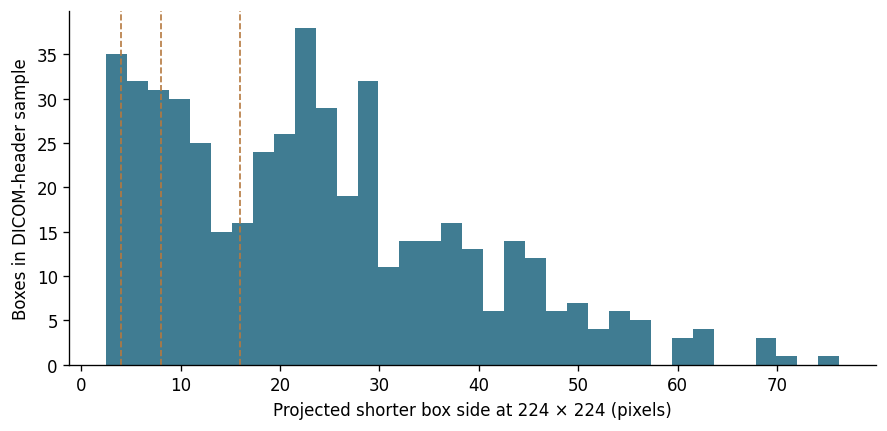

In [85]:
if not scaled.empty:
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.hist(scaled.short_side_224, bins=35, color="#407c92")
    for threshold in (4, 8, 16):
        ax.axvline(threshold, color="#b57940", lw=1, ls="--")
    ax.set(xlabel="Projected shorter box side at 224 × 224 (pixels)",
           ylabel="Boxes in DICOM-header sample")
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR / "projected_box_size_sample.png", dpi=180)
    plt.show()

### 10.9 Are small projected boxes equally frequent across labels?

In [86]:
if not scaled.empty:
    small_box_by_class = scaled.groupby("class_id").agg(
        boxes=("image_id", "size"),
        median_short_side_at_224=("short_side_224", "median"),
        pct_boxes_short_side_under_8=(
            "short_side_224", lambda x: 100 * (x < 8).mean()),
    )
    small_box_by_class.index = [
        CLASS_NAMES[int(i)] for i in small_box_by_class.index
    ]
    display(small_box_by_class.round(2))
    small_box_by_class.to_csv(OUTPUT_DIR / "projected_boxes_sample_by_class.csv")

,boxes,median_short_side_at_224,pct_boxes_short_side_under_8
Aortic enlargement,101,23.64,0.00
Atelectasis,4,40.85,0.00
Calcification,32,19.64,12.50
Cardiomegaly,81,30.64,0.00
Consolidation,1,48.24,0.00
ILD,18,43.69,5.56
Infiltration,7,44.98,0.00
Lung Opacity,21,29.57,0.00
Nodule/Mass,29,5.17,72.41
Other lesion,46,6.95,54.35


## 11. Summary of EDA Findings

After exploring the dataset, we found that the 67,914 annotation records correspond to 15,000 X-ray images, as each image may have multiple annotations from different radiologists. We also observed that the choice of labeling rule affects the number of positive samples. In particular, switching from union labeling to majority voting significantly reduces positive counts for several abnormalities.

Another important finding is the imbalance between classes. While *No finding* accounts for 70.76% of the training set, some abnormalities, such as Pneumothorax, have very few positive samples. Most images labeled with an abnormality also contain multiple positive labels, confirming the multi-label nature of our dataset.

During the data quality checks, we identified two identical PNG files with different image IDs in the training set, both labeled *No finding*. No identical files were found across the checked data splits. However, we could not verify patient-level independence because reliable patient identifiers were unavailable. We also observed that some annotated regions become very small after resizing to 224 × 224 pixels, which may affect the recognition of small abnormalities. These findings should be considered when interpreting the model's performance.